# 01 · Exploratory Data Analysis: Kiran Bazaar
**Question:** will the retail price of a food staple in a Pakistani city jump by more than **5 %** next month?

Data sources (see `data/README.md`):
1. **WFP Food Prices for Pakistan** (HDX, CC BY-IGO): monthly retail prices, 5 cities, 18 series, 2004-2026.
2. **WFP Markets for Pakistan** (HDX, CC BY-IGO): market metadata (province, latitude/longitude).
3. Inside (1), we use the **fuel (diesel, petrol)** and **labour wage** series and the **USD/PKR exchange rate** implied by `price / usdprice` as *external drivers* for food prices.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from kiranbazaar import config as C, features as F
FIG = C.FIG_DIR; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160, "display.max_columns", 40)

In [2]:
prices, markets = F.load_raw()
print(prices.shape); prices.head()

(14430, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2004-01-15,BALOCHISTAN,Quetta,Quetta,295,30.19,67.01,cereals and tubers,"Rice (basmati, broken)",122,KG,actual,Retail,PKR,20.00,0.35
1,2004-01-15,BALOCHISTAN,Quetta,Quetta,295,30.19,67.01,cereals and tubers,Wheat flour,58,KG,actual,Retail,PKR,13.00,0.23
2,2004-01-15,KHYBER PAKHTUNKHWA,Peshawar,Peshawar,294,34.01,71.58,cereals and tubers,"Rice (basmati, broken)",122,KG,actual,Retail,PKR,17.59,0.31
3,2004-01-15,KHYBER PAKHTUNKHWA,Peshawar,Peshawar,294,34.01,71.58,cereals and tubers,Wheat flour,58,KG,actual,Retail,PKR,12.00,0.21
4,2004-01-15,PUNJAB,Lahore,Lahore,291,31.55,74.34,cereals and tubers,"Rice (basmati, broken)",122,KG,actual,Retail,PKR,19.15,0.34


In [3]:
prices.info()

<class 'pandas.DataFrame'>
RangeIndex: 14430 entries, 0 to 14429
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          14430 non-null  datetime64[us]
 1   admin1        14430 non-null  str           
 2   admin2        14430 non-null  str           
 3   market        14430 non-null  str           
 4   market_id     14430 non-null  int64         
 5   latitude      14430 non-null  float64       
 6   longitude     14430 non-null  float64       
 7   category      14430 non-null  str           
 8   commodity     14430 non-null  str           
 9   commodity_id  14430 non-null  int64         
 10  unit          14430 non-null  str           
 11  priceflag     14430 non-null  str           
 12  pricetype     14430 non-null  str           
 13  currency      14430 non-null  str           
 14  price         14430 non-null  float64       
 15  usdprice      14430 non-null  float64       
dt

## 1. Overview: what is in the raw table

In [4]:
display(prices.describe(include="all").T[["count", "unique", "top", "mean", "min", "max"]])
print("markets with prices:", prices.market.unique())
print("duplicate (date, market, commodity) rows:", prices.duplicated(["date", "market", "commodity"]).sum())
print("constant columns:", [c for c in prices if prices[c].nunique() == 1])

,count,unique,top,mean,min,max
date,14430,NaN,NaN,2018-11-15 11:27:34.054054,2004-01-15 00:00:00,2026-10-15 00:00:00
admin1,14430,4,PUNJAB,NaN,NaN,NaN
admin2,14430,5,Peshawar,NaN,NaN,NaN
market,14430,5,Peshawar,NaN,NaN,NaN
market_id,14430.0,NaN,NaN,292.987179,291.0,295.0
latitude,14430.0,NaN,NaN,30.171559,24.91,34.01
longitude,14430.0,NaN,NaN,70.319094,67.01,74.34
category,14430,7,cereals and tubers,NaN,NaN,NaN
commodity,14430,18,"Rice (basmati, broken)",NaN,NaN,NaN
commodity_id,14430.0,NaN,NaN,157.048926,58.0,1378.0


markets with prices: <ArrowStringArray>
['Quetta', 'Peshawar', 'Lahore', 'Multan', 'Karachi']
Length: 5, dtype: str
duplicate (date, market, commodity) rows: 0
constant columns: ['priceflag', 'pricetype', 'currency']


`priceflag`, `pricetype` and `currency` are constant, so they are dropped. No personal identifiers exist (market-level aggregates only).
## 2. Missing values: coverage of each series over time

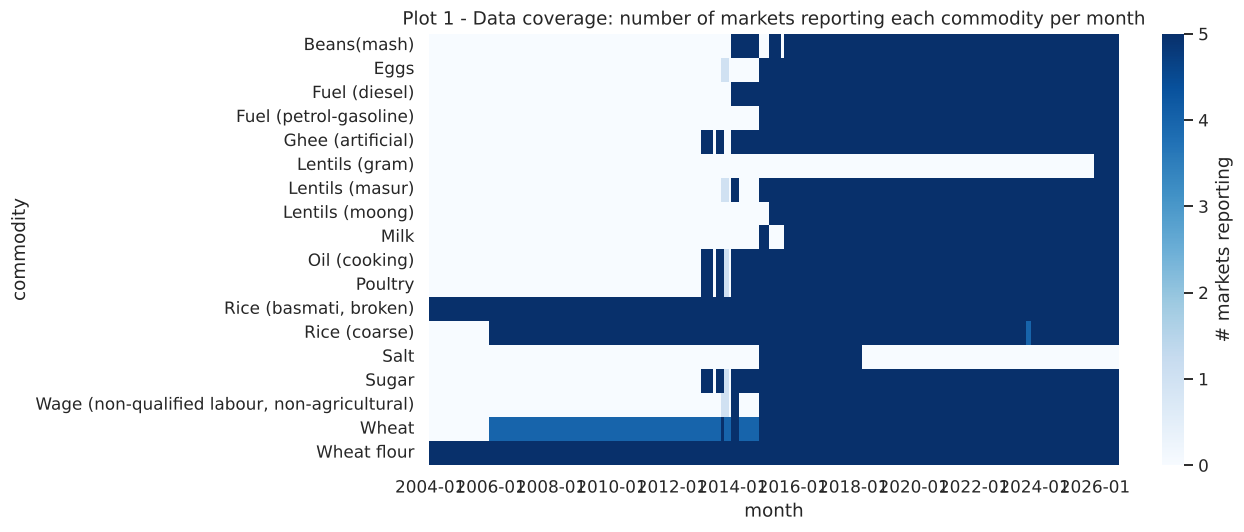

In [5]:
p = prices.assign(ym=prices.date.dt.to_period("M"))
cov = p.pivot_table(index="commodity", columns="ym", values="price", aggfunc="count")
full = pd.period_range(p.ym.min(), p.ym.max(), freq="M")
cov = cov.reindex(columns=full).fillna(0)
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(cov, cmap="Blues", cbar_kws={"label": "# markets reporting"}, ax=ax,
            xticklabels=24)
ax.set_title("Plot 1 - Data coverage: number of markets reporting each commodity per month")
ax.set_xlabel("month"); fig.tight_layout(); fig.savefig(FIG / "01_coverage_heatmap.png")

In [6]:
miss = 1 - cov.astype(bool).sum(axis=1) / len(full)
print("share of months with NO observation, per commodity"); miss.sort_values().round(3)

share of months with NO observation, per commodity


commodity
Rice (basmati, broken)                           0.000
Wheat flour                                      0.000
Wheat                                            0.088
Rice (coarse)                                    0.088
Sugar                                            0.401
Poultry                                          0.401
Oil (cooking)                                    0.401
Ghee (artificial)                                0.409
Fuel (diesel)                                    0.438
Wage (non-qualified labour, non-agricultural)    0.456
Beans(mash)                                      0.456
Lentils (masur)                                  0.456
Eggs                                             0.467
Fuel (petrol-gasoline)                           0.478
Lentils (moong)                                  0.493
Milk                                             0.500
Salt                                             0.850
Lentils (gram)                                   0.964


Rice and wheat start in 2004/2006; most other staples begin in 2013-2015. *Salt* stops in 2018 and *Lentils (gram)* only has 9 months, so both are dropped as targets. Gaps inside a series become NaN in the monthly grid and are imputed (median + missing-indicator) **inside** the Pipeline.
## 3. Distributions

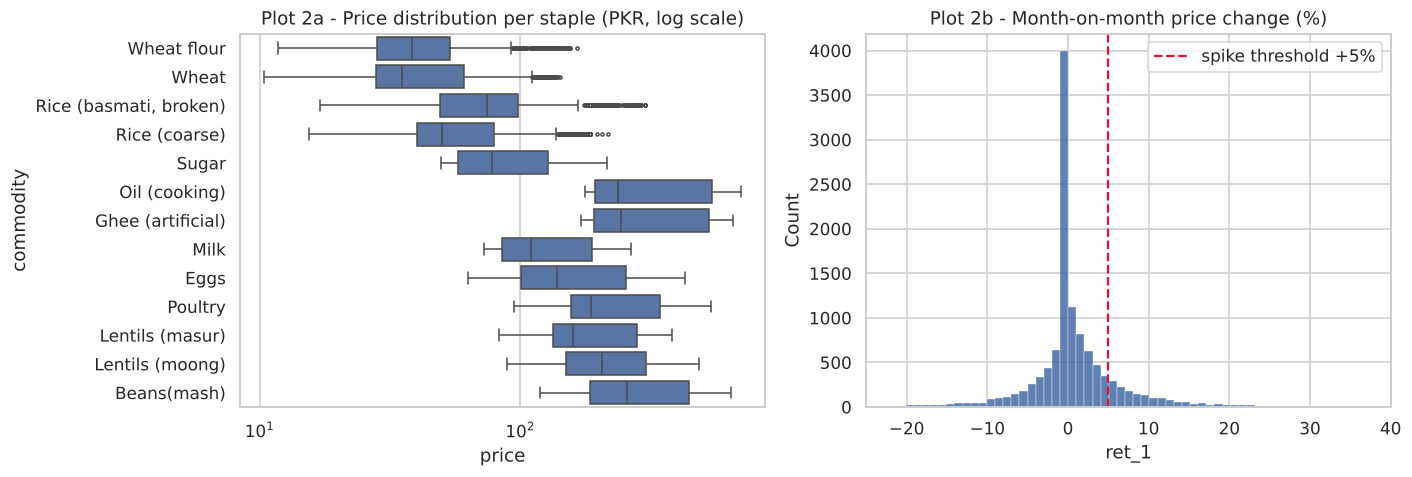

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=prices[prices.commodity.isin(C.TARGET_COMMODITIES)], y="commodity", x="price", ax=ax[0],
            fliersize=2, order=C.TARGET_COMMODITIES)
ax[0].set_xscale("log"); ax[0].set_title("Plot 2a - Price distribution per staple (PKR, log scale)")
feats = F.build_features(prices, markets)
sns.histplot(feats.ret_1.dropna() * 100, bins=120, ax=ax[1], color="#2b5797")
ax[1].axvline(5, color="crimson", ls="--", label="spike threshold +5%"); ax[1].set_xlim(-25, 40)
ax[1].set_title("Plot 2b - Month-on-month price change (%)"); ax[1].legend()
fig.tight_layout(); fig.savefig(FIG / "02_distributions.png")

Prices are right-skewed and span two orders of magnitude, so the model uses `log_price` and *percentage changes* instead of raw PKR. The monthly change is centred near 0 % with heavy tails: spikes are rare events.
## 4. Price trends and the exchange rate

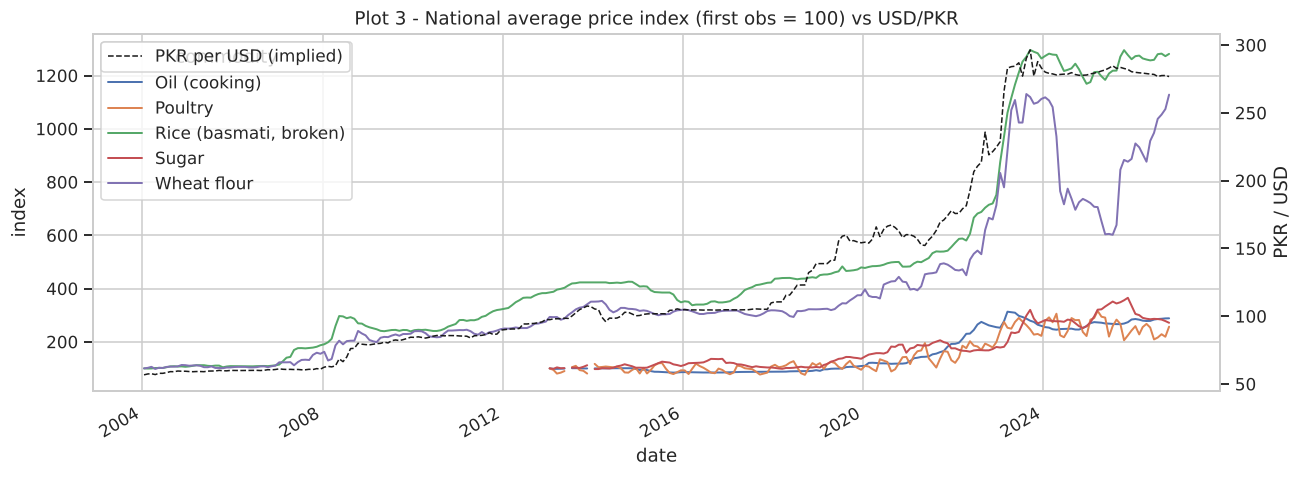

In [8]:
staples = ["Wheat flour", "Rice (basmati, broken)", "Sugar", "Oil (cooking)", "Poultry"]
nat = feats[feats.commodity.isin(staples)].groupby(["date", "commodity"]).price.mean().unstack()
fx = feats.groupby("date").fx_level.first()
fig, ax = plt.subplots(figsize=(12, 4.5))
(nat / nat.bfill().iloc[0] * 100).plot(ax=ax, lw=1.3)
ax2 = ax.twinx(); ax2.plot(fx.index, fx, "k--", lw=1, label="PKR per USD (implied)"); ax2.set_ylabel("PKR / USD")
ax2.grid(False); ax2.legend(loc="upper left")
ax.set(title="Plot 3 - National average price index (first obs = 100) vs USD/PKR", ylabel="index")
fig.tight_layout(); fig.savefig(FIG / "03_trends_fx.png")

Food prices follow the rupee: the sharp devaluations of 2018-19 and 2022-23 line up with steep rises in staples. This motivates the `fx_ret_1/3` features and warns us that the **2022-24 inflation shock** sits in the validation period (a regime shift).
## 5. Outliers

extreme (3xIQR) monthly changes per commodity:


,sum,mean
commodity,,
Beans(mash),4,0.005
Eggs,0,0.000
Ghee (artificial),140,0.176
Lentils (masur),32,0.044
Lentils (moong),22,0.032
Milk,86,0.127
Oil (cooking),115,0.144
Poultry,0,0.000
"Rice (basmati, broken)",176,0.129


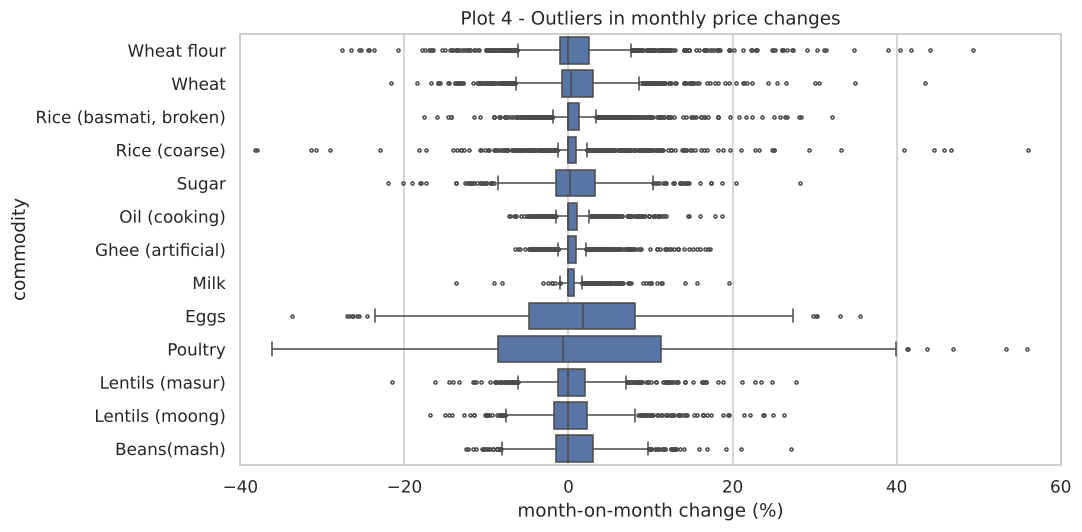

In [9]:
d = feats[["commodity", "ret_1"]].dropna()
q1, q3 = d.groupby("commodity").ret_1.transform(lambda s: s.quantile(.25)), d.groupby("commodity").ret_1.transform(lambda s: s.quantile(.75))
iqr = q3 - q1
d["outlier"] = (d.ret_1 < q1 - 3 * iqr) | (d.ret_1 > q3 + 3 * iqr)
print("extreme (3xIQR) monthly changes per commodity:"); display(d.groupby("commodity").outlier.agg(["sum", "mean"]).round(3))
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=d, x=d.ret_1 * 100, y="commodity", fliersize=2, ax=ax, order=C.TARGET_COMMODITIES)
ax.set(xlim=(-40, 60), xlabel="month-on-month change (%)", title="Plot 4 - Outliers in monthly price changes")
fig.tight_layout(); fig.savefig(FIG / "04_outliers.png")

Two patterns stand out. **Poultry and eggs** routinely move ±20-40 % in a month, so their IQR is wide and almost nothing counts as an outlier. **Rice, ghee, cooking oil and milk** are flat most months (IQR close to 0), so each occasional step change shows up as an "outlier". Both kinds are **real market events, not data errors**, and they are exactly what we want to predict, so we keep them. We use percentage changes (scale-free) and `StandardScaler`; the tree ensembles are insensitive to extreme values anyway.
## 6. Class balance

spike_next
0.0    8166
1.0    1467
Name: count, dtype: int64 
positive rate: 0.152


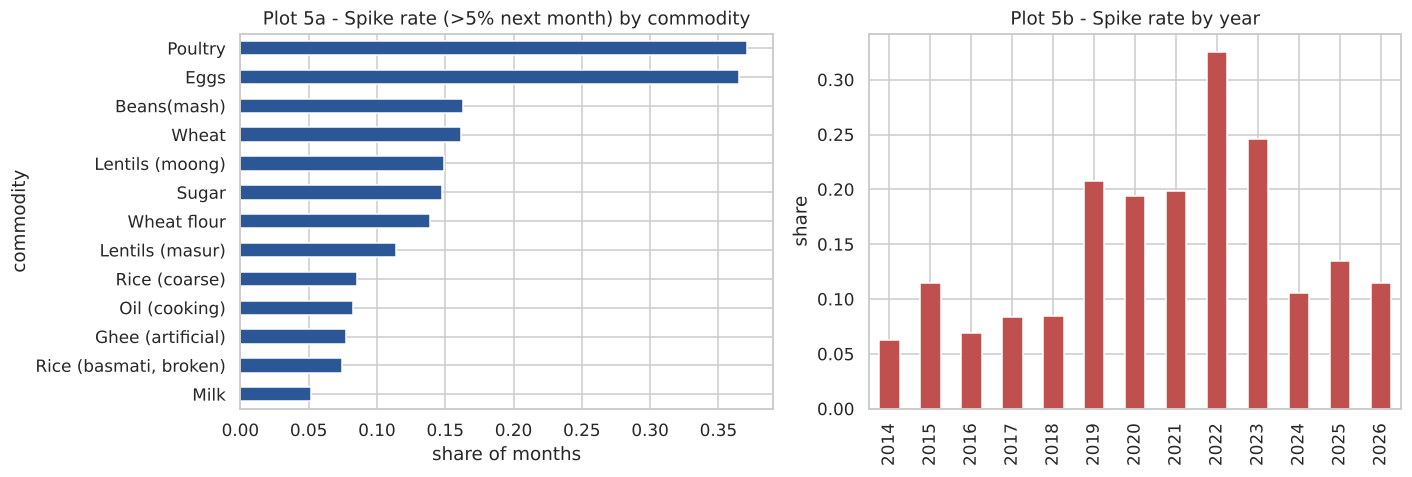

In [10]:
lab = F.labelled(feats)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
lab.groupby("commodity")[C.TARGET_CLF].mean().sort_values().plot.barh(ax=ax[0], color="#2b5797")
ax[0].set(title="Plot 5a - Spike rate (>5% next month) by commodity", xlabel="share of months")
yr = lab.groupby(lab.date.dt.year)[C.TARGET_CLF].mean()
yr.plot.bar(ax=ax[1], color="#c0504d"); ax[1].set(title="Plot 5b - Spike rate by year", ylabel="share", xlabel="")
fig.tight_layout(); fig.savefig(FIG / "05_class_balance.png")
print(lab[C.TARGET_CLF].value_counts(), "\npositive rate:", round(lab[C.TARGET_CLF].mean(), 3))

~15 % positives: imbalanced but learnable. We handle it with `class_weight="balanced"`, by tuning on ROC-AUC and by choosing the decision threshold on validation to maximise F1 (not the default 0.5). Accuracy would be misleading here: always saying "no spike" is already 85 % accurate.
## 7. Correlations

spikes_12       0.295
vol_6           0.292
nat_ret_1       0.174
ret_1           0.153
ret_12          0.124
ma_ratio_3      0.122
basket_ret_1    0.110
fx_ret_1        0.102
ret_2           0.100
fx_ret_3        0.080
Name: spike_next, dtype: float64

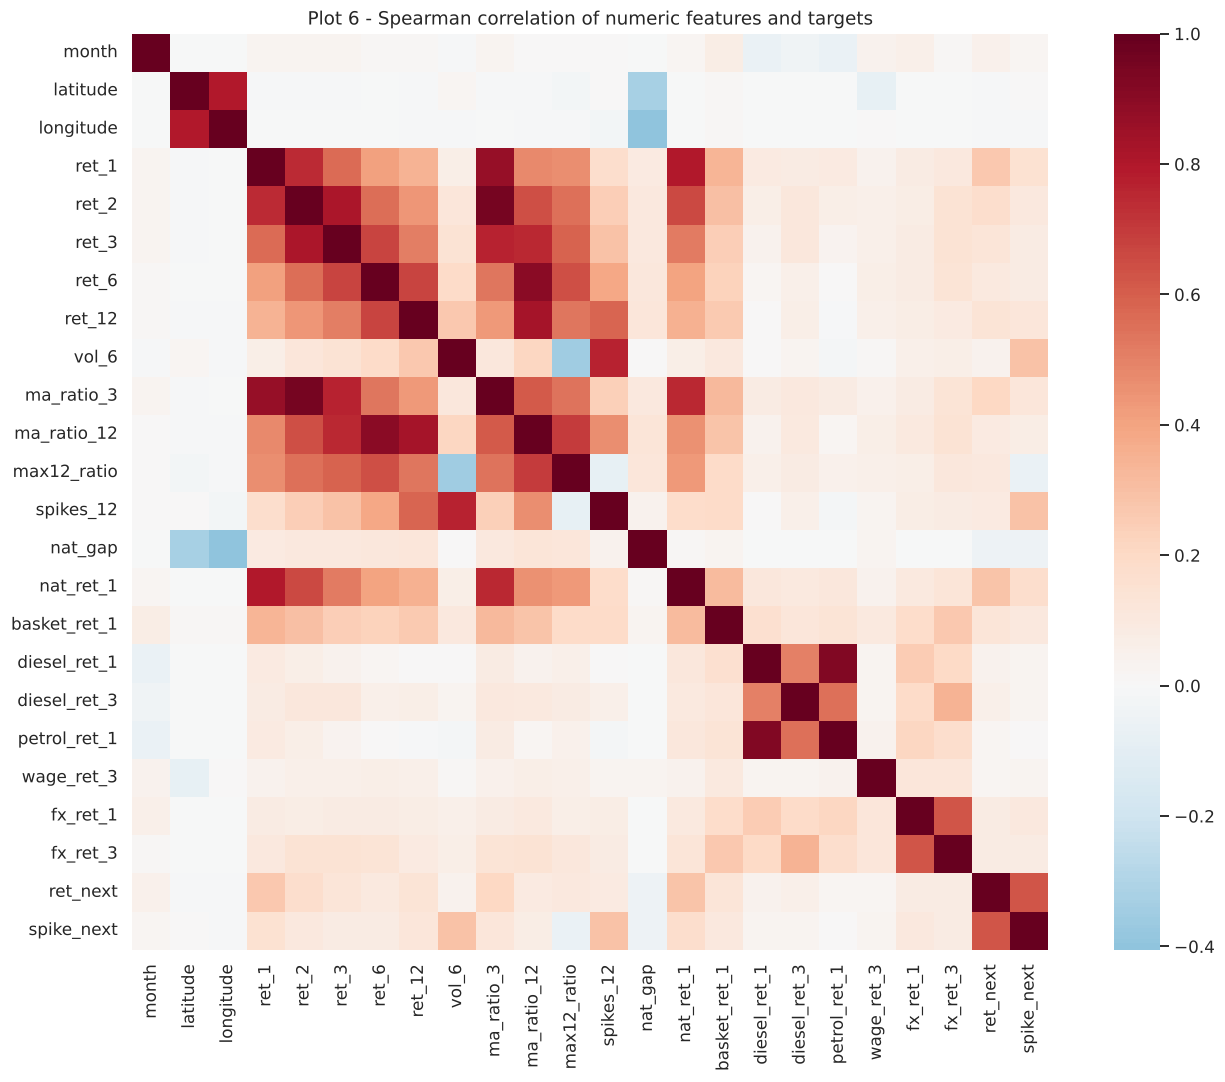

In [11]:
num = lab[C.NUMERIC_FEATURES + [C.TARGET_REG, C.TARGET_CLF]]
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, ax=ax, annot=False, square=True)
ax.set_title("Plot 6 - Spearman correlation of numeric features and targets")
fig.tight_layout(); fig.savefig(FIG / "06_correlation_heatmap.png")
corr[C.TARGET_CLF].drop([C.TARGET_CLF, C.TARGET_REG]).sort_values(key=abs, ascending=False).head(10).round(3)

The return features (`ret_1/2/3`, `ma_ratio_3`) are strongly inter-correlated, which suits regularised Logistic Regression and tree ensembles; Naive Bayes is expected to suffer because it assumes independence. The strongest single correlates of a spike are **recent volatility** (`spikes_12`, `vol_6`, ρ ≈ 0.29) and the **national momentum** of that commodity (`nat_ret_1`). Every correlation is weak to moderate, so a model has to combine many signals.
## 8. Seasonality

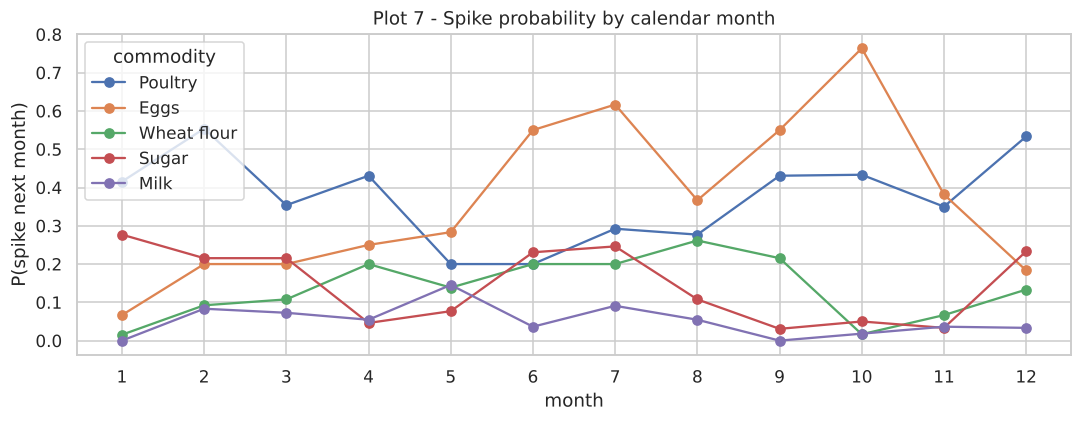

In [12]:
season = lab.groupby(["month", "commodity"])[C.TARGET_CLF].mean().unstack()[["Poultry", "Eggs", "Wheat flour", "Sugar", "Milk"]]
fig, ax = plt.subplots(figsize=(10, 4)); season.plot(ax=ax, marker="o")
ax.set(title="Plot 7 - Spike probability by calendar month", xlabel="month", ylabel="P(spike next month)", xticks=range(1, 13))
fig.tight_layout(); fig.savefig(FIG / "07_seasonality.png")

Poultry and eggs show clear seasonality (winter demand, summer heat losses), so the cyclical `month_sin/cos` features are built inside the pipeline.
## 9. Final modelling table

In [13]:
print("labelled rows:", len(lab), "| raw features:", len(C.CATEGORICAL_FEATURES + C.NUMERIC_FEATURES),
      "(+5 derived inside the pipeline)")
lab[C.CATEGORICAL_FEATURES + C.NUMERIC_FEATURES + [C.TARGET_CLF]].head()

labelled rows: 9633 | raw features: 26 (+5 derived inside the pipeline)


,market,commodity,category,province,month,latitude,longitude,ret_1,ret_2,ret_3,ret_6,ret_12,vol_6,ma_ratio_3,ma_ratio_12,max12_ratio,spikes_12,nat_gap,nat_ret_1,basket_ret_1,diesel_ret_1,diesel_ret_3,petrol_ret_1,wage_ret_3,fx_ret_1,fx_ret_3,spike_next
2237,Karachi,Beans(mash),pulses and nuts,SINDH,1,24.91,67.08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.076295,NaN,0.006684,NaN,NaN,NaN,NaN,-0.016182,-0.007413,0.0
2238,Karachi,Ghee (artificial),oil and fats,SINDH,1,24.91,67.08,NaN,NaN,NaN,-0.037037,0.029703,NaN,NaN,0.000000,-0.037037,0.0,0.012619,NaN,0.006684,NaN,NaN,NaN,NaN,-0.016182,-0.007413,0.0
2239,Karachi,Lentils (masur),pulses and nuts,SINDH,1,24.91,67.08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.054703,NaN,0.006684,NaN,NaN,NaN,NaN,-0.016182,-0.007413,0.0
2240,Karachi,Oil (cooking),oil and fats,SINDH,1,24.91,67.08,NaN,NaN,NaN,-0.027273,0.038835,NaN,NaN,-0.005692,-0.027273,0.0,-0.001120,NaN,0.006684,NaN,NaN,NaN,NaN,-0.016182,-0.007413,0.0
2241,Karachi,Poultry,"meat, fish and eggs",SINDH,1,24.91,67.08,NaN,0.626827,0.442073,0.353626,0.410027,0.163978,0.238625,0.321279,0.000000,3.0,0.121433,NaN,0.006684,NaN,NaN,NaN,NaN,-0.016182,-0.007413,0.0
